# **PART 1 – Employee Attrition**


In [195]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/content/drive/MyDrive/AXSOSACADEMY/01-Fundamentals/Week03/Data/Mod_employee_attrition - Temp employee_attrition.csv")
pd.set_option('display.max_columns',60)
df.head()

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,DailyRate,WeeklyRate,YearlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,752,3760,195520,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,Research & Development,8,1,Life Sciences,1,2,3,NaN,61,2,2,Research Scientist,2,Married,488,2440,126880,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,Research & Development,2,2,Other,1,4,4,NaN,92,2,1,Laboratory Technician,3,Single,736,3680,191360,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,448,2240,116480,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,Research & Development,2,1,Medical,1,7,1,NaN,40,3,1,Laboratory Technician,2,Married,320,1600,83200,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [196]:
df.shape

(1475, 35)

### **Section A - Data Cleaning**

In [197]:
df.duplicated().sum()

np.int64(5)

In [198]:
df = df.drop_duplicates()

In [199]:
df.duplicated().sum()

np.int64(0)

Five duplicate rows were identified and removed the dataset is now free
of fully duplicated rows.

In [200]:
df.dtypes

,0
Age,int64
Attrition,object
BusinessTravel,object
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64
EnvironmentSatisfaction,int64


In [201]:
for col in ['HourlyRate', 'YearsAtCompany']:
    print(col)
    print(df[pd.to_numeric(df[col], errors='coerce').isna()][col])

HourlyRate
9    94_
Name: HourlyRate, dtype: object
YearsAtCompany
36    5!
Name: YearsAtCompany, dtype: object


In [202]:
df['HourlyRate'] = df['HourlyRate'].replace('94_', '94')
df['YearsAtCompany'] = df['YearsAtCompany'].replace('5!', '5')

In [203]:
df['HourlyRate'] = df['HourlyRate'].astype(int)
df['YearsAtCompany'] = df['YearsAtCompany'].astype(int)

In [204]:
df[['HourlyRate', 'YearsAtCompany']].dtypes

,0
HourlyRate,int64
YearsAtCompany,int64


In [205]:
df.dtypes

,0
Age,int64
Attrition,object
BusinessTravel,object
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64
EnvironmentSatisfaction,int64


Two columns HourlyRate and YearsAtCompany were initially identified as object data types instead of integers the values 94_ and 5! contained unwanted characters. These characters were removed, and both columns were converted to integer data types  following the Data Dictionary.

In [206]:
for column in df.select_dtypes(include='object').columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


Attrition:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

BusinessTravel:
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Department:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

EducationField:
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Gender:
Gender
NaN       882
Female    588
Name: count, dtype: int64

JobRole:
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married  

In [207]:
df['Over18'] = df['Over18'].replace('Y', 'Yes')

In [208]:
df['Over18'].value_counts()

,count
Over18,
Yes,1470


Categorical values were checked for inconsistencies and the value Y in the Over18 column was standardized to Yes.

In [209]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0
EnvironmentSatisfaction,0


In [210]:
df['Gender'] = df['Gender'].fillna('Unknown')

In [211]:
df['Gender'].value_counts()

,count
Gender,
Unknown,882
Female,588


Missing values were found only in the Gender column and replaced with "Unknown"

In [212]:
df.describe()

,Age,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,DailyRate,WeeklyRate,YearlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,37.277551,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,527.129252,2635.646259,137053.605442,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,16.802435,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,162.635421,813.177104,42285.209396,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,240.000000,1200.000000,62400.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,384.000000,1920.000000,99840.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,528.000000,2640.000000,137280.000000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,670.000000,3350.000000,174200.000000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,578.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,800.000000,4000.000000,208000.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [213]:
df[df['Age'] > 100]

,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,DailyRate,WeeklyRate,YearlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
99,578,No,Travel_Rarely,Sales,10,4,Medical,1,131,4,Unknown,37,3,4,Sales Executive,3,Single,296,1480,76960,0,Yes,No,13,3,3,80,0,38,1,2,37,10,1,8


In [214]:
df.loc[df['Age'] > 100, 'Age'] = df['Age'].median()

An unrealistic age value (578) was identified and replaced with the median (36)and Other examined values were within their expected ranges

### **Section B - Exploratory Data Analysis**

Text(0.5, 1.0, 'Age Distribution')

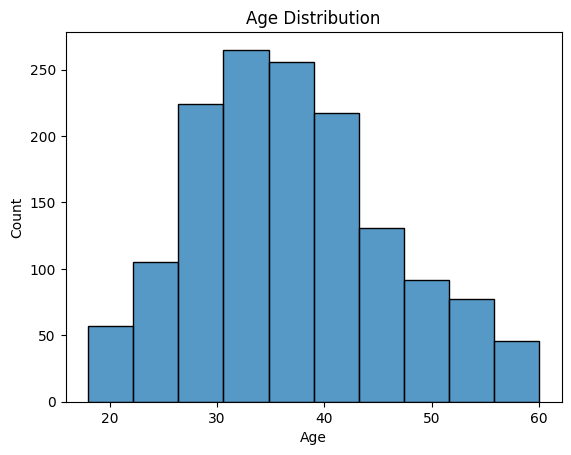

In [215]:
sns.histplot(data=df, x='Age', bins=10)
plt.title('Age Distribution')

The histogram shows that most employees are between 30 and 40 years old, while fewer employees are in the older age groups.

Text(0.5, 1.0, 'Employees by Department')

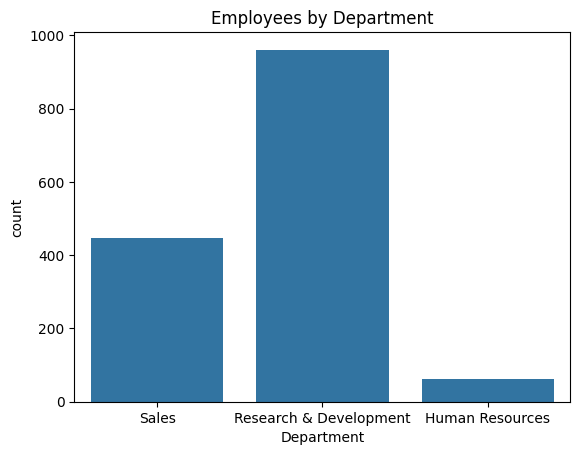

In [216]:
sns.countplot(data=df, x='Department')
plt.title('Employees by Department')

The Research & Development department has the highest number of employees followed by Sales, and Human Resources has the lowest number.

Text(0.5, 1.0, 'Daily Rate by Department')

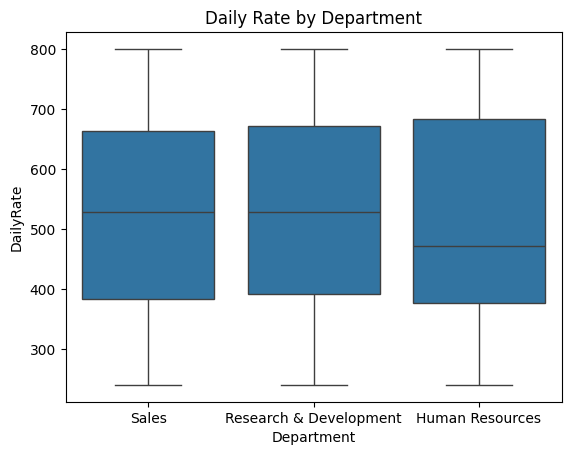

In [217]:
sns.boxplot(data=df, x='Department', y='DailyRate')
plt.title('Daily Rate by Department')

The distribution of DailyRate is similar across the three departments. Sales and Research & Development have slightly higher median values than Human Resources.

Text(0.5, 1.0, 'Correlation Heatmap')

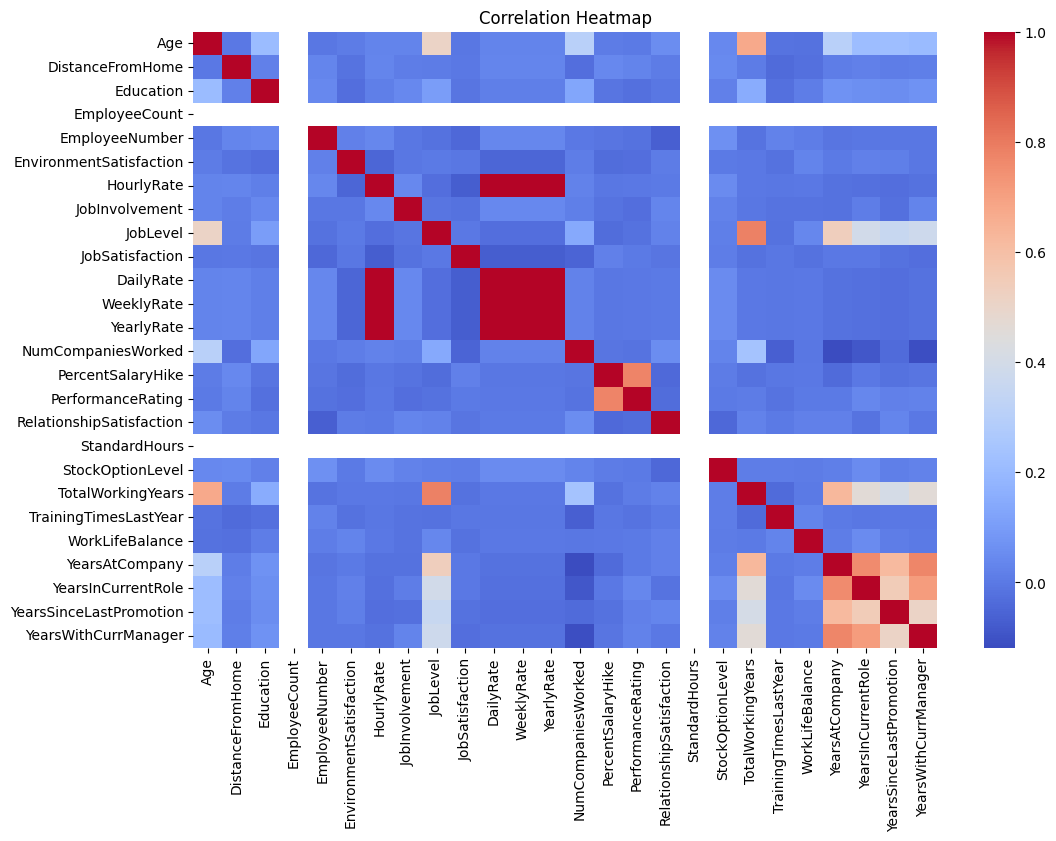

In [218]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include='number').corr(),cmap='coolwarm',annot=False)
plt.title('Correlation Heatmap')

The heatmap shows strong positive correlations between DailyRate, WeeklyRate, and YearlyRate. It also indicates positive correlations among YearsAtCompany, YearsInCurrentRole, and YearsWithCurrManager.

--------------------------------------------------------------------------------

# **Part 2: SQL - ShopSmart Database**

### **Task 1: Explore the Database**

In [219]:
from sqlalchemy import create_engine
engine = create_engine('sqlite:////content/drive/MyDrive/AXSOSACADEMY/01-Fundamentals/Week03/shopsmart.db')

In [220]:
conn = engine.connect()
q = """
SELECT name
FROM sqlite_master;
"""
tables = pd.read_sql(q, conn)
print(tables)

        name
0  Customers
1   Products
2     Orders


In [221]:
q1 = """
SELECT *
FROM Customers;
"""
Customerst = pd.read_sql(q1, conn)
Customerst

,customer_id,first_name,last_name,city
0,1,Lina,Abu Ali,Hebron
1,2,Khaled,Nasser,Ramallah
2,3,Sara,Qasem,Bethlehem
3,4,Lina,Hassan,Nablus
4,5,Lina,Issa,Ramallah
...,...,...,...,...
75,76,Adam,Saleh,Nablus
76,77,Omar,Nasser,Jenin
77,78,Noor,Khan,Nablus
78,79,Leen,Khan,Tulkarm


In [222]:
q2 = """
SELECT *
FROM Products;
"""
Productst = pd.read_sql(q2, conn)
Productst

,product_id,product_name,category,unit_price
0,1,Wireless Mouse,Electronics,18.0
1,2,Bluetooth Headphones,Electronics,45.0
2,3,USB-C Charger,Electronics,22.5
3,4,Laptop Stand,Electronics,32.0
4,5,Notebook Set,Stationery,8.0
5,6,Gel Pen Pack,Stationery,5.5
6,7,Desk Organizer,Stationery,14.0
7,8,Water Bottle,Home & Living,16.0
8,9,Ceramic Mug,Home & Living,12.0
9,10,Table Lamp,Home & Living,38.0


In [223]:
q3 = """
SELECT *
FROM Orders;
"""
orderst = pd.read_sql(q3, conn)
orderst

,order_id,customer_id,product_id,order_date,quantity,status,payment_method,discount
0,1,25,10,2025-04-22,8,Cancelled,Apple Pay,0.00
1,2,41,2,2025-01-26,3,Cancelled,Apple Pay,0.00
2,3,66,3,2025-04-06,1,Completed,Cash,0.05
3,4,73,8,2025-10-24,3,Cancelled,Credit Card,0.05
4,5,75,19,2025-09-25,2,Completed,Cash,0.10
...,...,...,...,...,...,...,...,...
295,296,66,14,2025-08-22,3,Cancelled,Bank Transfer,0.10
296,297,40,1,2025-07-22,2,Completed,Cash,0.10
297,298,6,14,2025-06-26,4,Cancelled,Credit Card,0.20
298,299,9,16,2025-01-17,2,Completed,Cash,0.15


The ShopSmart database contains three tables: Customers, Products, and Orders.

The Customers table contains 80 records and 4 columns.

The Products table contains 20 records and 4 columns.

The Orders table contains 300 records and 8 columns.

The column names and data types were displayed for each table to understand the database structure and identify the information available for further analysis.

### **Task 2: Basic Retrieval and Filtering**

In [224]:
q4 = """
SELECT *
FROM Customers;
"""
customers_col = pd.read_sql(q4, conn)
customers_col

,customer_id,first_name,last_name,city
0,1,Lina,Abu Ali,Hebron
1,2,Khaled,Nasser,Ramallah
2,3,Sara,Qasem,Bethlehem
3,4,Lina,Hassan,Nablus
4,5,Lina,Issa,Ramallah
...,...,...,...,...
75,76,Adam,Saleh,Nablus
76,77,Omar,Nasser,Jenin
77,78,Noor,Khan,Nablus
78,79,Leen,Khan,Tulkarm


In [225]:
q5 = """
SELECT *
FROM Orders
WHERE quantity > 3;
"""
orders_quantity = pd.read_sql(q5, conn)
orders_quantity

,order_id,customer_id,product_id,order_date,quantity,status,payment_method,discount
0,1,25,10,2025-04-22,8,Cancelled,Apple Pay,0.00
1,11,18,9,2025-03-01,6,Shipped,Apple Pay,0.00
2,12,37,20,2025-04-18,4,Completed,PayPal,0.10
3,14,17,9,2025-03-24,4,Cancelled,Bank Transfer,0.10
4,17,32,4,2025-07-01,5,Pending,Apple Pay,0.10
...,...,...,...,...,...,...,...,...
94,291,71,16,2025-10-03,5,Completed,Cash,0.10
95,293,73,4,2025-02-01,5,Cancelled,Cash,0.10
96,294,20,6,2025-06-17,6,Pending,Credit Card,0.10
97,295,75,16,2025-02-16,6,Pending,Credit Card,0.05


In [226]:
q6 = """
SELECT *
FROM Customers
WHERE city = 'Ramallah' OR city = 'Nablus';
"""
selected_customers = pd.read_sql(q6, conn)
selected_customers

,customer_id,first_name,last_name,city
0,2,Khaled,Nasser,Ramallah
1,4,Lina,Hassan,Nablus
2,5,Lina,Issa,Ramallah
3,6,Rami,Saleh,Ramallah
4,7,Rana,None,Nablus
5,9,Rana,Nasser,Nablus
6,10,Hala,Hassan,Ramallah
7,11,Ahmad,Masri,Ramallah
8,14,Tariq,Darwish,Ramallah
9,16,Sara,Khalil,Ramallah


In [227]:
q7 = """
SELECT *
FROM Orders
WHERE status = 'Completed'
AND quantity > 2;
"""
completed_orders = pd.read_sql(q7, conn)
completed_orders

,order_id,customer_id,product_id,order_date,quantity,status,payment_method,discount
0,12,37,20,2025-04-18,4,Completed,PayPal,0.10
1,13,33,2,2025-02-17,3,Completed,Credit Card,0.00
2,15,15,3,2025-03-18,3,Completed,Apple Pay,0.10
3,18,31,6,2025-04-01,6,Completed,Cash,0.10
4,30,27,14,2025-10-24,3,Completed,Bank Transfer,0.05
...,...,...,...,...,...,...,...,...
62,269,25,8,2025-05-23,3,Completed,PayPal,0.15
63,277,61,16,2025-04-13,4,Completed,PayPal,0.00
64,279,23,14,2025-04-01,7,Completed,Bank Transfer,0.15
65,289,40,4,2025-11-24,7,Completed,PayPal,0.10


In this task, SQL queries were used to retrieve and filter data from the ShopSmart database.

All customer records were retrieved from the Customers table.

Orders with a quantity greater than 3 were selected.

Customers located in Ramallah or Nablus were identified.

Completed orders with a quantity greater than 2 were retrieved.

### **Task 3 – Results and Interpretation**

In [228]:
q8 = """
SELECT *
FROM Products
ORDER BY unit_price DESC;
"""
products_sorted = pd.read_sql(q8, conn)
products_sorted

,product_id,product_name,category,unit_price
0,20,Smart Watch,Electronics,115.0
1,2,Bluetooth Headphones,Electronics,45.0
2,17,Backpack,Accessories,42.0
3,10,Table Lamp,Home & Living,38.0
4,14,Skin Care Set,Beauty,34.0
5,4,Laptop Stand,Electronics,32.0
6,19,Sunglasses,Accessories,29.0
7,11,Yoga Mat,Sports,27.0
8,18,Wallet,Accessories,25.0
9,3,USB-C Charger,Electronics,22.5


In [229]:
q9 = """
SELECT COUNT(*) AS Total_Orders
FROM Orders;
"""
total_orders = pd.read_sql(q9, conn)
total_orders

,Total_Orders
0,300


In [230]:
q10 = """
SELECT SUM(quantity) AS total_quantity
FROM Orders;
"""
total_quantity = pd.read_sql(q10, conn)
total_quantity

,total_quantity
0,981


In [231]:
q11 = """
SELECT AVG(unit_price) AS average_price
FROM Products;
"""
average_price = pd.read_sql(q11, conn)
average_price

,average_price
0,26.75


In this task, SQL queries were used to sort and calculate summary statistics from the ShopSmart database.

All products were sorted by unit price in descending order, from the highest price to the lowest.

The total number of orders was calculated as 300.

The total quantity of products ordered was calculated using the SUM() function.

The average price of all products was calculated as 26.75 using the AVG() function.

### **Task 4 – Grouping Data**

In [232]:
qtask4 = """
SELECT category,
       AVG(unit_price) AS Average_Price,
       COUNT(*) AS Product_Count
FROM Products
GROUP BY category
ORDER BY Average_Price DESC;
"""
category_analysis = pd.read_sql(q12, conn)
category_analysis

,first_name,last_name,city,order_id,order_date,status
0,Omar,Saleh,Nablus,1,2025-04-22,Cancelled
1,Lina,Abu Ali,Ramallah,2,2025-01-26,Cancelled
2,Rami,Masri,Ramallah,3,2025-04-06,Completed
3,Ahmad,Khalil,Nablus,4,2025-10-24,Cancelled
4,Khaled,Nasser,Tulkarm,5,2025-09-25,Completed
...,...,...,...,...,...,...
295,Rami,Masri,Ramallah,296,2025-08-22,Cancelled
296,Tariq,Odeh,Nablus,297,2025-07-22,Completed
297,Rami,Saleh,Ramallah,298,2025-06-26,Cancelled
298,Rana,Nasser,Nablus,299,2025-01-17,Completed


In this task, the GROUP BY clause was used to group products by category. The AVG() function calculated the average product price for each category, while COUNT() calculated the number of products in each category. The results were sorted in descending order based on the average price.

### **Task 5: Joining Tables**

In [233]:
q12 = """
SELECT
    c.first_name,
    c.last_name,
    c.city,
    o.order_id,
    o.order_date,
    o.status
FROM Customers AS c
INNER JOIN Orders AS o
ON c.customer_id = o.customer_id;
"""
customer_orders = pd.read_sql(q12, conn)
customer_orders

,first_name,last_name,city,order_id,order_date,status
0,Omar,Saleh,Nablus,1,2025-04-22,Cancelled
1,Lina,Abu Ali,Ramallah,2,2025-01-26,Cancelled
2,Rami,Masri,Ramallah,3,2025-04-06,Completed
3,Ahmad,Khalil,Nablus,4,2025-10-24,Cancelled
4,Khaled,Nasser,Tulkarm,5,2025-09-25,Completed
...,...,...,...,...,...,...
295,Rami,Masri,Ramallah,296,2025-08-22,Cancelled
296,Tariq,Odeh,Nablus,297,2025-07-22,Completed
297,Rami,Saleh,Ramallah,298,2025-06-26,Cancelled
298,Rana,Nasser,Nablus,299,2025-01-17,Completed


In [234]:
q13 = """
SELECT
    c.first_name,
    c.last_name,
    c.city,
    o.order_id,
    p.product_name,
    p.category,
    p.unit_price,
    o.quantity,
    o.discount,
    o.payment_method
FROM Customers AS c
INNER JOIN Orders AS o
ON c.customer_id = o.customer_id
INNER JOIN Products AS p
ON o.product_id = p.product_id;
"""
customer_order_products = pd.read_sql(q13, conn)
customer_order_products

,first_name,last_name,city,order_id,product_name,category,unit_price,quantity,discount,payment_method
0,Omar,Saleh,Nablus,1,Table Lamp,Home & Living,38.0,8,0.00,Apple Pay
1,Lina,Abu Ali,Ramallah,2,Bluetooth Headphones,Electronics,45.0,3,0.00,Apple Pay
2,Rami,Masri,Ramallah,3,USB-C Charger,Electronics,22.5,1,0.05,Cash
3,Ahmad,Khalil,Nablus,4,Water Bottle,Home & Living,16.0,3,0.05,Credit Card
4,Khaled,Nasser,Tulkarm,5,Sunglasses,Accessories,29.0,2,0.10,Cash
...,...,...,...,...,...,...,...,...,...,...
295,Rami,Masri,Ramallah,296,Skin Care Set,Beauty,34.0,3,0.10,Bank Transfer
296,Tariq,Odeh,Nablus,297,Wireless Mouse,Electronics,18.0,2,0.10,Cash
297,Rami,Saleh,Ramallah,298,Skin Care Set,Beauty,34.0,4,0.20,Credit Card
298,Rana,Nasser,Nablus,299,Hand Cream,Beauty,11.0,2,0.15,Cash


In this task, INNER JOIN was used to combine data from related tables.

In Question 12, the Customers and Orders tables were joined using the customer_id column to display customer and order information.

In Question 13, the Customers, Orders, and Products tables were joined using their related ID columns to retrieve customer, order, and product information.

In [235]:
q14 = """
SELECT
    c.customer_id,
    c.first_name,
    c.last_name,
    c.city,
    o.order_id,
    o.order_date,
    o.status,
    o.quantity,
    o.discount,
    o.payment_method,
    p.product_id,
    p.product_name,
    p.category,
    p.unit_price
FROM Customers c
INNER JOIN Orders o
ON c.customer_id = o.customer_id
INNER JOIN Products p
ON o.product_id = p.product_id;
"""

df = pd.read_sql(q14, conn)
df

,customer_id,first_name,last_name,city,order_id,order_date,status,quantity,discount,payment_method,product_id,product_name,category,unit_price
0,25,Omar,Saleh,Nablus,1,2025-04-22,Cancelled,8,0.00,Apple Pay,10,Table Lamp,Home & Living,38.0
1,41,Lina,Abu Ali,Ramallah,2,2025-01-26,Cancelled,3,0.00,Apple Pay,2,Bluetooth Headphones,Electronics,45.0
2,66,Rami,Masri,Ramallah,3,2025-04-06,Completed,1,0.05,Cash,3,USB-C Charger,Electronics,22.5
3,73,Ahmad,Khalil,Nablus,4,2025-10-24,Cancelled,3,0.05,Credit Card,8,Water Bottle,Home & Living,16.0
4,75,Khaled,Nasser,Tulkarm,5,2025-09-25,Completed,2,0.10,Cash,19,Sunglasses,Accessories,29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,66,Rami,Masri,Ramallah,296,2025-08-22,Cancelled,3,0.10,Bank Transfer,14,Skin Care Set,Beauty,34.0
296,40,Tariq,Odeh,Nablus,297,2025-07-22,Completed,2,0.10,Cash,1,Wireless Mouse,Electronics,18.0
297,6,Rami,Saleh,Ramallah,298,2025-06-26,Cancelled,4,0.20,Credit Card,14,Skin Care Set,Beauty,34.0
298,9,Rana,Nasser,Nablus,299,2025-01-17,Completed,2,0.15,Cash,16,Hand Cream,Beauty,11.0


In Question 14, an SQL query was created to join the Customers, Orders, and Products tables using INNER JOIN.

In Question 15, the query was executed, and the results were stored in a Pandas DataFrame named df.

-------------------------------------------------------------------------------